# Mission and propulsion verification

This notebook continues the **shared 6DOF state** through coast, restart and finite-burn departure, checks source mission geometry, and exposes propulsion calculations. A C3 energy target is not a full Mars intercept or a departure-vector targeting solution.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from hyperion.workspace import current_flight
from hyperion.verification import ROOT, activities, input_contracts

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_colwidth', 100)

In [2]:
from hyperion.mission import integrated_tmi, lambert_window
context = current_flight()
# Explicit screening assumptions: coast duration and an additional restart debit.
COAST_SECONDS = 600.0
RESTART_PROPELLANT_KG = context[2].c['vehicle']['stages'][1]['startup_propellant_kg']
TARGET_C3 = 9.8  # PERF.2.01, still under review; master mission case uses 7.7058.
tmi = integrated_tmi(context=context, coast_duration_s=COAST_SECONDS,
    restart_propellant_kg=RESTART_PROPELLANT_KG, target_c3_km2_s2=TARGET_C3,
    max_burn_duration_s=900, output_step_s=2)
display(pd.DataFrame([{key: tmi[key] for key in ['status','target_C3_km2_s2',
    'achieved_C3_km2_s2','C3_margin_km2_s2','remaining_propellant_kg','required_residual_kg']}]))

,status,target_C3_km2_s2,achieved_C3_km2_s2,C3_margin_km2_s2,remaining_propellant_kg,required_residual_kg
0,residual_propellant_limit,9.8,-12.253672,-22.053672,1917.145795,1917.145795


The burn stops at the target, residual inventory, ground contact or time limit. Prograde guidance, restart propellant, coast duration and absent coast control are explicit assumptions. A fuel-limited result must remain a failure even if the ideal rocket-equation estimate looks adequate.

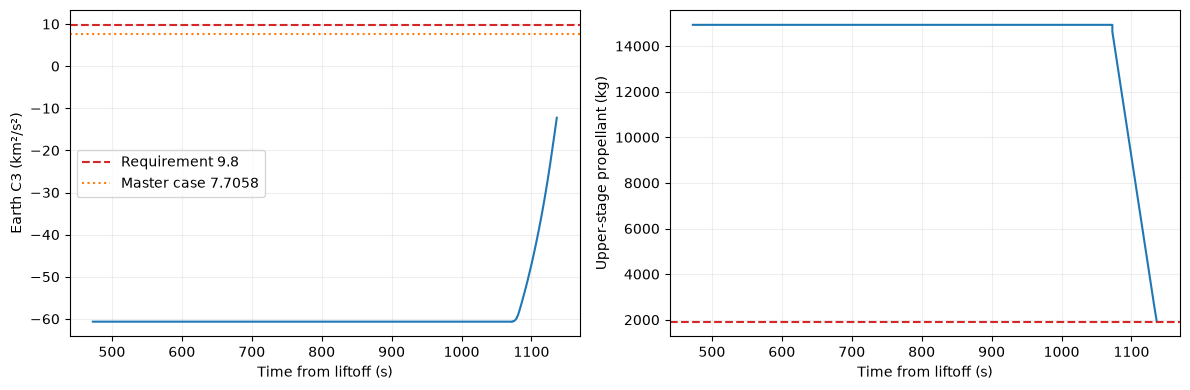

In [3]:
departure = pd.DataFrame(tmi['history'])
r = departure[['eci_x_m','eci_y_m','eci_z_m']].to_numpy()
v = departure[['eci_vx_m_s','eci_vy_m_s','eci_vz_m_s']].to_numpy()
from hyperion.trajectory import MU
c3 = (np.sum(v*v, axis=1) - 2*MU/np.linalg.norm(r,axis=1))/1e6
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(departure.t_s, c3)
axes[0].axhline(TARGET_C3, ls='--', color='tab:red', label='Requirement 9.8')
axes[0].axhline(7.7058, ls=':', color='tab:orange', label='Master case 7.7058')
axes[0].set(xlabel='Time from liftoff (s)', ylabel='Earth C3 (km²/s²)'); axes[0].legend()
axes[1].plot(departure.t_s, departure.prop2_kg)
axes[1].axhline(tmi['required_residual_kg'], ls='--', color='tab:red')
axes[1].set(xlabel='Time from liftoff (s)', ylabel='Upper-stage propellant (kg)')
plt.tight_layout(); plt.show()

## Departure geometry

Three 274-day Earth–Mars transfers use the synchronized design team's Horizons states for 27–29 April 2033. Inputs are Sun-centered equatorial ICRF, geometric states in TDB. This small sweep verifies the solver/data path; daily launch windows still need launch-site timing, finite-burn targeting and approved constraints.

In [4]:
mission_cases = json.loads((ROOT/'config/mission_cases.json').read_text())
window = lambert_window(cases=mission_cases['cases'], central_mu_m3_s2=mission_cases['central_mu_m3_s2'])
display(pd.DataFrame(window['cases'])[['departure_label','departure_C3_km2_s2',
    'departure_declination_deg','arrival_excess_speed_m_s']].round(4))

,departure_label,departure_C3_km2_s2,departure_declination_deg,arrival_excess_speed_m_s
0,2033-04-27 00:00 TDB,7.7237,-10.3665,4375.8107
1,2033-04-28 00:00 TDB,7.7090,-11.3763,4376.2099
2,2033-04-29 00:00 TDB,7.7055,-12.4805,4376.2699


## Propulsion inputs and additional studies

The library includes nozzle expansion, thrust/Isp, propellant consumption, throttle dynamics, feed pressure loss, fill/drain timing, ullage pressure, boiloff, chilldown and residual inventory. Missing geometry, chamber thermochemistry, pressure setpoints and valve/controller laws must be supplied before those activities can produce vehicle evidence. Tests and hot-fire records remain separate.

For payload, wind and separation sensitivity studies, use the listed functions with explicit scenario distributions and seeds. Their default inputs never invent design uncertainty.

In [5]:
contracts = input_contracts()
from hyperion import mission, propulsion
display(contracts[contracts.calculation.isin(set(mission.FUNCTIONS)|set(propulsion.FUNCTIONS))])

,calculation,required_inputs,description
0,integrated_tmi,"coast_duration_s, restart_propellant_kg, target_c3_km2_s2, max_burn_duration_s","Reuse or run the ascent, then continue from its actual orbital-speed cutoff."
1,finite_burn_tmi,"cutoff_row, config, coast_duration_s, restart_propellant_kg, target_c3_km2_s2, max_burn_duration_s","Continue an ascent-cutoff state through coast, restart, and finite TMI."
2,lambert,"departure_position_m, arrival_position_m, time_of_flight_s, central_mu_m3_s2",Zero-revolution universal-variable solution; endpoints share one inertial frame.
3,lambert_window,"cases, central_mu_m3_s2",Evaluate supplied ephemeris/date pairs; no fabricated planet ephemerides.
4,relative_separation,"position_a_m, velocity_a_m_s, position_b_m, velocity_b_m_s, mass_a_kg, mass_b_kg, impulse_on_a_N...",Propagate both released bodies with equal/opposite impulse and gravity.
5,rocket_equation,"initial_mass_kg, final_mass_kg, isp_s",
6,propellant_budget,"loaded_mass_kg, burns_kg, startup_kg, boiloff_kg, trapped_residual_kg, required_reserve_kg",
7,payload_sweep,payload_masses_kg,Rerun the shared ascent for each supplied payload; no mass rescaling shortcut.
8,finite_tmi_payload_sweep,"payload_masses_kg, coast_duration_s, restart_propellant_kg, target_c3_km2_s2, max_burn_duration_s",Repeat both shared 6DOF ascent and departure for each requested payload mass.
9,tmi_cutoff_sensitivity,"cutoff_row, config, burn_durations_s, coast_duration_s, restart_propellant_kg, target_c3_km2_s2","Sweep prescribed TMI shutdown times, still stopping at propellant residual."
